
# UTS Graf Sains Data — Bagian 2.1
## Wrangling dan Exploratory Data Analysis (EDA)

### Tujuan
Analisis ini bertujuan untuk melakukan pemfilteran data interaksi
RetailRocket berdasarkan periode waktu, mengeksplorasi komposisi
subgraph pada Neo4j, membangun Vector Space Model (VSM) untuk User
dan Item, membandingkan proyeksi graf, serta menghitung dan menyimpan
similarity ke dalam Neo4j.

### Periode analisis
- P1 (Training): 1–15 Juli 2015.
- P2 (Testing): 16–31 Agustus 2015.

### Sumber data
Dataset RetailRocket dengan atribut timestamp, visitorid, event,
itemid, dan transactionid.

Timestamp pada dataset berbentuk Unix epoch dalam milidetik.


# Import library dan konfigurasi

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from getpass import getpass

from scipy.sparse import coo_matrix, save_npz
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors
from neo4j import GraphDatabase

# Lokasi file
INPUT_CSV = "data/events.csv"
P1_FILE = "data/P1.csv"
P2_FILE = "data/P2.csv"
OUTPUT_DIR = "output_21"

# Koneksi Neo4j  (REVISI: password tidak boleh ditulis di notebook yang akan diunggah ke GitHub)
URI = os.getenv("NEO4J_URI", "bolt://localhost:7687")
USERNAME = os.getenv("NEO4J_USER", "neo4j")
PASSWORD = os.getenv("NEO4J_PASSWORD") or getpass("Password Neo4j: ")

# Parameter analisis
CHUNK_SIZE = 200_000
TOP_K = 5
RANDOM_SEED = 42

# Bobot interaksi untuk VSM
EVENT_WEIGHTS = {"view": 1.0, "addtocart": 3.0, "transaction": 5.0}

# REVISI: periode didefinisikan SEKALI di sini, lalu dipakai oleh filter CSV dan semua query Neo4j
def timestamp_ms(tanggal_utc):
    """Tanggal UTC -> Unix epoch milidetik (bilangan bulat)."""
    return int(pd.Timestamp(tanggal_utc, tz="UTC").value // 1_000_000)


PERIODE = {
    "P1": (timestamp_ms("2015-07-01"), timestamp_ms("2015-07-16")),   # 1-15 Juli 2015 (akhir eksklusif)
    "P2": (timestamp_ms("2015-08-16"), timestamp_ms("2015-09-01")),   # 16-31 Agustus 2015
}
p1_start, p1_end = PERIODE["P1"]
p2_start, p2_end = PERIODE["P2"]


def jalankan_cypher(query, **parameter):
    """Menjalankan query Cypher dan mengembalikan hasilnya sebagai DataFrame."""
    with GraphDatabase.driver(URI, auth=(USERNAME, PASSWORD)) as driver:
        with driver.session() as session:
            return pd.DataFrame([dict(r) for r in session.run(query, **parameter)])


# Uji koneksi langsung di sel ini, supaya salah password langsung terlihat
try:
    with GraphDatabase.driver(URI, auth=(USERNAME, PASSWORD)) as driver:
        driver.verify_connectivity()
    print("Koneksi Neo4j berhasil.")
except Exception as e:
    raise RuntimeError(
        f"Gagal terhubung ke Neo4j ({type(e).__name__}). Periksa USERNAME dan PASSWORD, "
        "lalu jalankan ulang sel ini."
    ) from e


os.makedirs("data", exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Library berhasil diimpor.")
print("File dataset tersedia:", os.path.exists(INPUT_CSV))
print("Folder output:", OUTPUT_DIR)


Koneksi Neo4j berhasil.
Library berhasil diimpor.
File dataset tersedia: True
Folder output: output_21


C:\Users\User\AppData\Local\Temp\ipykernel_42696\3801024488.py:57: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Library digunakan untuk pengolahan data, perhitungan kemiripan, visualisasi graf, dan koneksi ke Neo4j. Password Neo4j dimasukkan secara interaktif menggunakan getpass agar tidak tersimpan langsung di notebook. Periode P1 dan P2 didefinisikan dalam timestamp UTC milidetik dan digunakan secara konsisten untuk filter CSV serta query Neo4j. Fungsi jalankan_cypher() memudahkan eksekusi query dan konversi hasilnya menjadi DataFrame. Folder data dan output dibuat otomatis jika belum tersedia.

# 1. Pemfilteran periode


## 1. Pemfilteran Data Interaksi

Data interaksi dipisahkan menjadi dua periode. P1 digunakan sebagai
periode training, sedangkan P2 digunakan sebagai periode testing.

Pemfilteran dilakukan berdasarkan atribut timestamp. Batas akhir
setiap periode bersifat eksklusif agar tanggal di luar periode tidak
ikut terambil. Hasil pemfilteran disimpan dalam file P1.csv dan P2.csv.


# 2. Filter dan simpan CSV

In [2]:
def filter_periods():
    if not os.path.exists(INPUT_CSV):
        raise FileNotFoundError(f"Dataset tidak ditemukan: {INPUT_CSV}")

    # Hapus output lama agar tidak tercampur
    for path in [P1_FILE, P2_FILE]:
        if os.path.exists(path):
            os.remove(path)

    total_p1 = 0
    total_p2 = 0
    header_p1 = True
    header_p2 = True

    for chunk in pd.read_csv(INPUT_CSV, chunksize=CHUNK_SIZE):
        chunk["timestamp"] = pd.to_numeric(
            chunk["timestamp"], errors="coerce"
        )
        chunk = chunk.dropna(subset=["timestamp"])

        p1 = chunk[
            (chunk["timestamp"] >= p1_start)
            & (chunk["timestamp"] < p1_end)
        ]

        p2 = chunk[
            (chunk["timestamp"] >= p2_start)
            & (chunk["timestamp"] < p2_end)
        ]

        if not p1.empty:
            p1.to_csv(
                P1_FILE, mode="a", index=False, header=header_p1
            )
            total_p1 += len(p1)
            header_p1 = False

        if not p2.empty:
            p2.to_csv(
                P2_FILE, mode="a", index=False, header=header_p2
            )
            total_p2 += len(p2)
            header_p2 = False

    print(f"Jumlah event P1: {total_p1:,}")
    print(f"Jumlah event P2: {total_p2:,}")

    return total_p1, total_p2


jumlah_p1, jumlah_p2 = filter_periods()

Jumlah event P1: 333,778
Jumlah event P2: 287,853


Proses filter data berhasil memisahkan dataset menjadi dua periode berdasarkan timestamp. Periode P1 menghasilkan 333.778 event, sedangkan periode P2 menghasilkan 287.853 event. Hasil ini digunakan untuk memisahkan data training dan testing agar analisis dan evaluasi rekomendasi dapat dilakukan.

## EDA sederhana hasil filter


### Pemeriksaan Hasil Pemfilteran

Tahap ini memeriksa jumlah data, jenis interaksi, jumlah pengunjung
unik, dan jumlah item unik pada setiap periode. Pemeriksaan ini
digunakan untuk memastikan bahwa hasil filter dapat digunakan pada
analisis berikutnya.


In [3]:
def ringkasan_csv(path, nama_periode):
    if not os.path.exists(path):
        print(f"{nama_periode}: file belum tersedia.")
        return None

    df = pd.read_csv(path)

    print(f"\n===== {nama_periode} =====")
    print("Jumlah baris:", f"{len(df):,}")
    print("Jumlah visitor unik:", f"{df['visitorid'].nunique():,}")
    print("Jumlah item unik:", f"{df['itemid'].nunique():,}")

    print("\nKomposisi event:")
    print(df["event"].value_counts().to_string())

    return df


df_p1 = ringkasan_csv(P1_FILE, "P1 - TRAINING")
df_p2 = ringkasan_csv(P2_FILE, "P2 - TESTING")



===== P1 - TRAINING =====
Jumlah baris: 333,778
Jumlah visitor unik: 185,205
Jumlah item unik: 87,308

Komposisi event:
event
view           322990
addtocart        8099
transaction      2689

===== P2 - TESTING =====
Jumlah baris: 287,853
Jumlah visitor unik: 163,714
Jumlah item unik: 79,399

Komposisi event:
event
view           277534
addtocart        7778
transaction      2541



Data P1 digunakan sebagai data training dengan 333.778 event, 185.205 visitor unik, dan 87.308 item unik. Sementara itu, data P2 digunakan sebagai data testing dengan 287.853 event, 163.714 visitor unik, dan 79.399 item unik.

Pada kedua periode, event *view* memiliki jumlah terbanyak, disusul *addtocart* dan *transaction*. Hal ini menunjukkan bahwa sebagian besar aktivitas pengguna adalah melihat item, sedangkan aktivitas menambahkan ke keranjang dan melakukan transaksi jumlahnya lebih sedikit.

In [4]:
# EDA tambahan: seberapa besar P1 dan P2 beririsan? (menentukan seberapa banyak user bisa dievaluasi di 2.2)
v1, v2 = set(df_p1["visitorid"]), set(df_p2["visitorid"])
i1, i2 = set(df_p1["itemid"]), set(df_p2["itemid"])

df_overlap = pd.DataFrame({
    "P1": [len(v1), len(i1)],
    "P2": [len(v2), len(i2)],
    "Irisan P1 dan P2": [len(v1 & v2), len(i1 & i2)],
    "% dari P2 yang juga ada di P1": [100 * len(v1 & v2) / len(v2), 100 * len(i1 & i2) / len(i2)],
}, index=["Visitor", "Item"])
display(df_overlap.round(2))


,P1,P2,Irisan P1 dan P2,% dari P2 yang juga ada di P1
Visitor,185205,163714,3070,1.88
Item,87308,79399,42576,53.62


Berdasarkan perbandingan P1 dan P2, terdapat 3.070 visitor yang muncul pada kedua periode, yaitu 1,88% dari total visitor P2. Sementara itu, terdapat 42.576 item yang muncul pada kedua periode, yaitu 53,62% dari total item P2.

Hal ini menunjukkan bahwa sebagian besar item pada data testing sudah pernah muncul pada data training, tetapi sebagian besar visitor pada P2 merupakan visitor yang berbeda dari P1.

# 3. Komposisi Subgraph
Subgraph yang digunakan pada penelitian ini merepresentasikan interaksi pengunjung (Visitor) terhadap produk (Item) pada dataset RetailRocket. Jenis simpul yang diamati adalah Visitor dan Item. Jumlah setiap jenis simpul diperoleh melalui query Cypher pada Neo4j dan diakses menggunakan Python API melalui library neo4j.

Hasil query digunakan untuk mengetahui komposisi simpul pada graf sebelum dilakukan proses Vector Space Modelling (VSM).

## Query Cypher menggunakan Python API

In [5]:
# 3. Komposisi subgraph P1 dan P2: jenis simpul, jumlahnya, dan jenis relasi

# Hitung simpul unik dan relasi yang timestamp-nya jatuh dalam periode [awal, akhir)
Q_SIMPUL = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.timestamp >= $awal AND r.timestamp < $akhir
RETURN count(DISTINCT v) AS jumlah_visitor,
       count(DISTINCT i) AS jumlah_item,
       count(r)          AS jumlah_relasi
"""

# Rincian jumlah relasi per jenis
Q_RELASI = """
MATCH (:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
WHERE r.timestamp >= $awal AND r.timestamp < $akhir
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
"""

PETA_EVENT = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
baris = []
for nama, df_csv in [("P1", df_p1), ("P2", df_p2)]:
    awal, akhir = PERIODE[nama]
    s = jalankan_cypher(Q_SIMPUL, awal=awal, akhir=akhir).iloc[0]
    rel = jalankan_cypher(Q_RELASI, awal=awal, akhir=akhir).set_index("jenis_relasi")["jumlah"]
    baris += [(nama, "Simpul Visitor", int(s["jumlah_visitor"])), (nama, "Simpul Item", int(s["jumlah_item"]))]
    baris += [(nama, f"Relasi {jenis}", int(n)) for jenis, n in rel.sort_index().items()]

    # Validasi: isi Neo4j harus sama dengan CSV hasil filter (menangkap impor ganda atau data tidak lengkap)
    csv_rel = df_csv["event"].map(PETA_EVENT).value_counts()
    cocok = (rel.reindex(csv_rel.index).eq(csv_rel).all()
             and int(s["jumlah_visitor"]) == df_csv["visitorid"].nunique()
             and int(s["jumlah_item"]) == df_csv["itemid"].nunique())
    print(f"{nama}: isi Neo4j sama dengan CSV hasil filter -> {cocok}")

df_komposisi = (pd.DataFrame(baris, columns=["periode", "jenis", "jumlah"])
                .pivot(index="jenis", columns="periode", values="jumlah"))
display(df_komposisi)


P1: isi Neo4j sama dengan CSV hasil filter -> True
P2: isi Neo4j sama dengan CSV hasil filter -> True


periode,P1,P2
jenis,,
Relasi ADDED_TO_CART,8099,7778
Relasi BOUGHT,2689,2541
Relasi VIEWED,322990,277534
Simpul Item,87308,79399
Simpul Visitor,185205,163714


Berdasarkan hasil analisis, komposisi subgraph P1 dan P2 berhasil dihitung berdasarkan jumlah simpul Visitor, simpul Item, dan jenis relasi. Pada kedua periode, relasi VIEWED memiliki jumlah terbanyak, diikuti ADDED_TO_CART dan BOUGHT. Hasil validasi menunjukkan nilai True pada P1 dan P2, yang berarti data di Neo4j sudah sesuai dengan data CSV hasil filter dan tidak ditemukan perbedaan jumlah data.

# 4. VSM (Vector Space Model)

## Ambil interaksi dari P1Ambil interaksi dari P1

Kita gunakan P1 (1–15 Juli 2015) sebagai data training. Bobot interaksi yang sudah ditentukan sebelumnya adalah:

Jenis interaksi	| Bobot

view	            1

addtocart	        3

transaction	        5

Artinya, interaksi pembelian diberi bobot lebih tinggi daripada melihat item saja.

In [6]:
# Mengambil interaksi dari P1 

query_vsm_visitor = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.timestamp >= $awal AND r.timestamp < $akhir
WITH v, i,
     sum(CASE type(r)
             WHEN 'VIEWED'        THEN $w_view
             WHEN 'ADDED_TO_CART' THEN $w_cart
             WHEN 'BOUGHT'        THEN $w_buy
             ELSE 0.0
         END) AS bobot
RETURN v.visitorId AS visitorId,
       i.itemId AS itemId,
       bobot
"""

df_interaksi_p1 = jalankan_cypher(
    query_vsm_visitor,
    awal=p1_start, akhir=p1_end,
    w_view=EVENT_WEIGHTS["view"],
    w_cart=EVENT_WEIGHTS["addtocart"],
    w_buy=EVENT_WEIGHTS["transaction"],
)

print("Jumlah baris interaksi Visitor-Item:", len(df_interaksi_p1))
display(df_interaksi_p1.head())


Jumlah baris interaksi Visitor-Item: 266342


,visitorId,itemId,bobot
0,62710,355908,1.0
1,144258,355908,1.0
2,781493,355908,1.0
3,473952,355908,1.0
4,1384406,355908,1.0


Berdasarkan hasil pengambilan data dari Neo4j, terdapat 266.342 pasangan interaksi antara Visitor dan Item pada periode P1. Data ini menunjukkan hubungan antara pengunjung dan item yang pernah dilihat, ditambahkan ke keranjang, atau dibeli. Setiap pasangan memiliki nilai bobot yang digunakan untuk menghitung tingkat kemiripan antaritem. Selanjutnya, data ini akan digunakan untuk membuat matriks interaksi sebagai dasar dalam membangun sistem rekomendasi item.

## Bentuk matriks VSM

In [7]:
# Membentuk matriks VSM Visitor dengan sparse matrix

from scipy.sparse import coo_matrix

# Daftar ID Visitor dan Item yang ada pada data P1
visitor_ids = sorted(df_interaksi_p1["visitorId"].unique())
item_ids = sorted(df_interaksi_p1["itemId"].unique())

# Pemetaan ID ke indeks baris dan kolom
visitor_to_idx = {
    visitor_id: idx
    for idx, visitor_id in enumerate(visitor_ids)
}

item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

# Mengubah ID menjadi indeks numerik
baris = df_interaksi_p1["visitorId"].map(visitor_to_idx).to_numpy()
kolom = df_interaksi_p1["itemId"].map(item_to_idx).to_numpy()
nilai = df_interaksi_p1["bobot"].to_numpy(dtype=np.float32)

# Membuat matriks sparse Visitor × Item
matriks_visitor = coo_matrix(
    (nilai, (baris, kolom)),
    shape=(len(visitor_ids), len(item_ids)),
    dtype=np.float32
).tocsr()

# Menggabungkan nilai jika terdapat koordinat yang berulang
matriks_visitor.sum_duplicates()

print("Shape VSM Visitor:", matriks_visitor.shape)
print("Jumlah Visitor:", matriks_visitor.shape[0])
print("Jumlah Item:", matriks_visitor.shape[1])
print("Jumlah elemen nonzero:", matriks_visitor.nnz)
print(
    "Ukuran data matriks:",
    f"{matriks_visitor.data.nbytes / (1024**2):.2f} MB"
)

Shape VSM Visitor: (185205, 87308)
Jumlah Visitor: 185205
Jumlah Item: 87308
Jumlah elemen nonzero: 266342
Ukuran data matriks: 1.02 MB


Matriks VSM Visitor berhasil dibuat dengan ukuran 185.205 baris dan 87.308 kolom. Baris menunjukkan jumlah Visitor, sedangkan kolom menunjukkan jumlah Item pada data P1. Matriks ini memiliki 266.342 elemen yang berisi nilai interaksi antara Visitor dan Item. Proses ini menggunakan sparse matrix, yaitu cara menyimpan data yang hanya mencatat nilai yang terisi, sehingga penggunaan memori lebih hemat. Ukuran penyimpanan matriks hanya 1,02 MB, sehingga lebih efisien untuk mengolah data yang berukuran besar.

## Menampilkan contoh matriks VSM

In [8]:
# Menampilkan sampel VSM

sampel_vsm = matriks_visitor[:5, :5].toarray()

df_sampel_vsm = pd.DataFrame(
    sampel_vsm,
    index=visitor_ids[:5],
    columns=item_ids[:5]
)

print("Contoh matriks VSM Visitor (5 × 5):")
display(df_sampel_vsm)

Contoh matriks VSM Visitor (5 × 5):


,6,9,15,16,25
9,0.0,0.0,0.0,0.0,0.0
20,0.0,0.0,0.0,0.0,0.0
22,0.0,0.0,0.0,0.0,0.0
36,0.0,0.0,0.0,0.0,0.0
43,0.0,0.0,0.0,0.0,0.0


Contoh matriks VSM Visitor berukuran 5 × 5 menunjukkan hubungan antara 5 Visitor dan 5 Item. Nilai 0.0 pada seluruh bagian matriks berarti kelima Visitor tersebut tidak memiliki interaksi dengan kelima Item yang ditampilkan. Hal ini dapat terjadi karena setiap Visitor hanya berinteraksi dengan sebagian kecil dari seluruh Item yang tersedia. Oleh karena itu, penggunaan sparse matrix lebih efisien karena hanya menyimpan nilai yang memiliki interaksi.

## Fungsi Bantu untuk Analisis VSM dan Visualisasi Graf Proyeksi

In [9]:
# Fungsi bantu untuk no. 4-6 (letakkan setelah sel yang membentuk matriks_visitor)
import time
from scipy.sparse.csgraph import connected_components


def karakteristik_vsm(M, simpul, fitur):
    """Ringkasan VSM. simpul = entitas pada baris, fitur = entitas pada kolom (= dimensi ruang vektor)."""
    n_baris, n_kolom = M.shape
    per_baris, per_kolom = M.getnnz(axis=1), M.getnnz(axis=0)
    ringkas = lambda x: f"{np.median(x):.0f} / {x.mean():.2f} / {x.max()}"
    return pd.Series({
        f"Dimensi ruang vektor (1 {simpul} = vektor {n_kolom:,} dimensi)": n_kolom,
        "Shape": f"{n_baris:,} x {n_kolom:,}",
        "ndim array": M.ndim,
        "Elemen tersimpan (nonzero)": f"{M.nnz:,}",
        "Kepadatan (%)": f"{M.nnz / (n_baris * n_kolom) * 100:.6f}",
        f"{fitur} per {simpul} (median / rata-rata / maks)": ringkas(per_baris),
        f"{simpul} per {fitur} (median / rata-rata / maks)": ringkas(per_kolom),
        f"% {simpul} yang hanya punya 1 {fitur}": f"{(per_baris == 1).mean() * 100:.1f}",
        "Memori sparse (MB)": f"{(M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1024**2:.2f}",
        "Memori jika dense float32 (GB)": f"{n_baris * n_kolom * 4 / 1024**3:.1f}",
    }, name=f"VSM {simpul}")


def sampel_terhubung(B, n_perantara=6, deg_min=5, deg_max=30, maks_simpul=100, seed=RANDOM_SEED):
    """Sampel yang PASTI memuat sisi proyeksi (100 ID pertama hampir semuanya terisolasi).
    B: baris = simpul yang diproyeksikan, kolom = simpul perantara.
    Ambil n_perantara kolom acak berderajat deg_min..deg_max, lalu semua baris yang terhubung ke kolom itu."""
    rng = np.random.default_rng(seed)
    Bc = B.tocsc()
    derajat = Bc.getnnz(axis=0)
    kandidat = np.flatnonzero((derajat >= deg_min) & (derajat <= deg_max))
    if len(kandidat) == 0:
        kandidat = np.argsort(-derajat)[:n_perantara]
    kolom = np.sort(rng.choice(kandidat, size=min(n_perantara, len(kandidat)), replace=False))
    baris = np.unique(np.concatenate([Bc.indices[Bc.indptr[j]:Bc.indptr[j + 1]] for j in kolom]))
    if len(baris) > maks_simpul:
        baris = np.sort(rng.choice(baris, size=maks_simpul, replace=False))
    return baris, kolom


def graf_proyeksi(B, baris, label):
    """Proyeksi biner B[baris] @ B[baris].T menjadi graf NetworkX (bobot sisi = jumlah perantara bersama)."""
    Bs = B[baris].copy()
    Bs.data[:] = 1
    P = (Bs @ Bs.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    G = nx.from_scipy_sparse_array(P)
    return nx.relabel_nodes(G, {i: label[b] for i, b in enumerate(baris)})


def gambar_graf(G, judul, file=None):
    derajat = dict(G.degree())
    pos = nx.spring_layout(G, seed=RANDOM_SEED, k=0.4)
    fig, ax = plt.subplots(figsize=(11, 7))
    nx.draw_networkx_edges(G, pos, width=0.5, alpha=0.4, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_size=[30 + 10 * derajat[n] for n in G],
                           node_color=[derajat[n] for n in G], cmap=plt.cm.viridis, ax=ax)
    ax.set_title(f"{judul}\n{G.number_of_nodes()} simpul, {G.number_of_edges()} sisi, "
                 f"{nx.number_connected_components(G)} komponen terhubung")
    ax.axis("off")
    if file:
        fig.savefig(file, dpi=200, bbox_inches="tight")
    plt.show()


Kode ini merupakan kumpulan fungsi pendukung untuk mempermudah analisis karakteristik VSM dan visualisasi graf pada tahap berikutnya. Fungsi-fungsi ini belum menjalankan analisis secara langsung karena perlu dipanggil terlebih dahulu.

## VSM Visitor: karakteristik, sampel matriks, dan plot NetworkX

,VSM Visitor
"Dimensi ruang vektor (1 Visitor = vektor 87,308 dimensi)",87308
Shape,"185,205 x 87,308"
ndim array,2
Elemen tersimpan (nonzero),"266,342"
Kepadatan (%),0.001647
Item per Visitor (median / rata-rata / maks),1 / 1.44 / 888
Visitor per Item (median / rata-rata / maks),1 / 3.05 / 410
% Visitor yang hanya punya 1 Item,83.1
Memori sparse (MB),2.74
Memori jika dense float32 (GB),60.2


Sampel: 68 visitor yang berinteraksi dengan 6 item acak (masing-masing 5-30 visitor)


,41942,205864,208470,303520,358963,397865
62033,0.0,4.0,0.0,0.0,0.0,0.0
64135,0.0,0.0,0.0,0.0,0.0,3.0
73163,0.0,0.0,0.0,1.0,0.0,0.0
88080,0.0,1.0,0.0,0.0,0.0,0.0
168283,0.0,0.0,2.0,0.0,0.0,0.0
170503,0.0,0.0,0.0,1.0,0.0,0.0
180413,0.0,0.0,0.0,0.0,1.0,0.0
190365,1.0,0.0,0.0,0.0,0.0,0.0


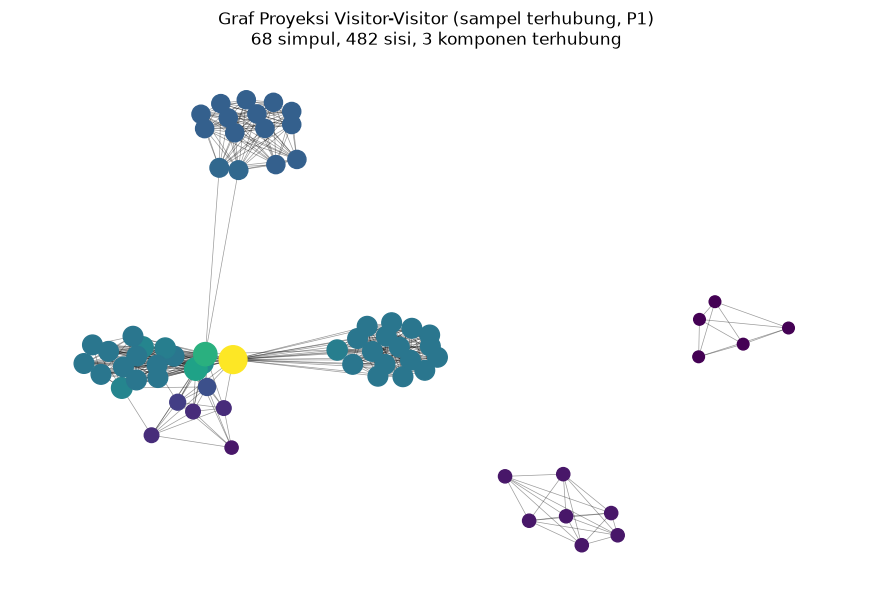

In [10]:
# No. 4 — VSM Visitor: karakteristik, sampel matriks, dan plot NetworkX
display(karakteristik_vsm(matriks_visitor, "Visitor", "Item").to_frame())

baris_v, kolom_v = sampel_terhubung(matriks_visitor, n_perantara=6, deg_min=5, deg_max=30)
print(f"Sampel: {len(baris_v)} visitor yang berinteraksi dengan 6 item acak (masing-masing 5-30 visitor)")
display(pd.DataFrame(matriks_visitor[baris_v[:8]][:, kolom_v].toarray(),
                     index=[visitor_ids[i] for i in baris_v[:8]],
                     columns=[item_ids[j] for j in kolom_v]))        # irisan 8 visitor x 6 item (bukan 5x5 yang nol semua)

G_visitor = graf_proyeksi(matriks_visitor, baris_v, visitor_ids)
gambar_graf(G_visitor, "Graf Proyeksi Visitor-Visitor (sampel terhubung, P1)",
            os.path.join(OUTPUT_DIR, "graf_proyeksi_visitor.png"))


### Interpretasi VSM Visitor

Matriks VSM Visitor memiliki 185.205 baris dan 87.308 kolom, dengan 266.342 elemen yang terisi. Kepadatan matriks hanya 0,001647%, sehingga sebagian besar nilainya kosong. Oleh karena itu, penggunaan *sparse matrix* lebih hemat memori, yaitu 2,74 MB dibandingkan sekitar 60,2 GB jika disimpan dalam bentuk matriks biasa (*dense matrix*).

Hasil analisis menunjukkan bahwa 83,1% Visitor hanya berinteraksi dengan satu Item. Pada sampel matriks, nilai selain nol menunjukkan adanya interaksi antara Visitor dan Item tertentu.

### Interpretasi Graf Proyeksi Visitor-Visitor

Graf proyeksi menunjukkan hubungan antar-Visitor yang berinteraksi dengan Item yang sama. Berdasarkan visualisasi, terdapat 68 simpul, 482 sisi, dan 3 komponen terhubung. Kelompok simpul yang saling terhubung menunjukkan adanya Visitor yang memiliki kesamaan item interaksi, sedangkan kelompok yang terpisah menunjukkan tidak adanya hubungan dengan kelompok lainnya dalam sampel graf tersebut.

# 5. VSM untuk simpul Item

## VSM untuk simpul Item

In [11]:
# Membentuk VSM Item dengan sparse matrix

# Membalik matriks Visitor × Item menjadi Item × Visitor
matriks_item = matriks_visitor.T.tocsr()

print("Shape VSM Item:", matriks_item.shape)
print("Jumlah Item:", matriks_item.shape[0])
print("Jumlah Visitor:", matriks_item.shape[1])
print("Jumlah elemen tersimpan:", matriks_item.nnz)
print(
    "Ukuran data matriks:",
    f"{matriks_item.data.nbytes / (1024**2):.2f} MB"
)

Shape VSM Item: (87308, 185205)
Jumlah Item: 87308
Jumlah Visitor: 185205
Jumlah elemen tersimpan: 266342
Ukuran data matriks: 1.02 MB


Matriks VSM Item dibentuk dengan membalik matriks VSM Visitor, sehingga baris menunjukkan Item dan kolom menunjukkan Visitor. Matriks ini memiliki 87.308 Item dan 185.205 Visitor, dengan 266.342 elemen yang terisi. Ukuran penyimpanan datanya hanya 1,02 MB karena menggunakan sparse matrix, yang hanya menyimpan nilai interaksi yang terisi. Matriks ini digunakan untuk melihat pola interaksi setiap Item dengan Visitor dan menjadi dasar untuk menghitung kemiripan antaritem dalam sistem rekomendasi.

## Menampilkan contoh matriks VSM Item

In [12]:
# Menampilkan sampel matriks VSM Item (5 × 5)

sampel_vsm_item = matriks_item[:5, :5].toarray()

df_sampel_vsm_item = pd.DataFrame(
    sampel_vsm_item,
    index=item_ids[:5],
    columns=visitor_ids[:5]
)

print("Contoh matriks VSM Item (5 Item × 5 Visitor):")
display(df_sampel_vsm_item)

Contoh matriks VSM Item (5 Item × 5 Visitor):


,9,20,22,36,43
6,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0
15,0.0,0.0,0.0,0.0,0.0
16,0.0,0.0,0.0,0.0,0.0
25,0.0,0.0,0.0,0.0,0.0


Contoh matriks VSM Item berukuran 5 × 5 menunjukkan hubungan antara 5 Item dan 5 Visitor. Semua nilai pada matriks adalah 0, yang berarti kelima Item tersebut tidak memiliki interaksi dengan kelima Visitor yang ditampilkan. Hal ini terjadi karena setiap Item hanya berinteraksi dengan sebagian dari seluruh Visitor. Oleh karena itu, contoh matriks ini belum menunjukkan hubungan interaksi, tetapi tetap menggambarkan bentuk matriks yang digunakan dalam analisis.

## VSM Item: karakteristik, sampel matriks, dan plot NetworkX

,VSM Item
"Dimensi ruang vektor (1 Item = vektor 185,205 dimensi)",185205
Shape,"87,308 x 185,205"
ndim array,2
Elemen tersimpan (nonzero),"266,342"
Kepadatan (%),0.001647
Visitor per Item (median / rata-rata / maks),1 / 3.05 / 410
Item per Visitor (median / rata-rata / maks),1 / 1.44 / 888
% Item yang hanya punya 1 Visitor,52.9
Memori sparse (MB),2.37
Memori jika dense float32 (GB),60.2


Sampel: 31 item yang dilihat oleh 8 visitor acak (masing-masing berinteraksi dengan 3-15 item)


,117023,121299,602351,610909,911542,972238,1081155,1206634
12523,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
43725,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
68607,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
75867,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
82141,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
88553,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
95834,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
102048,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


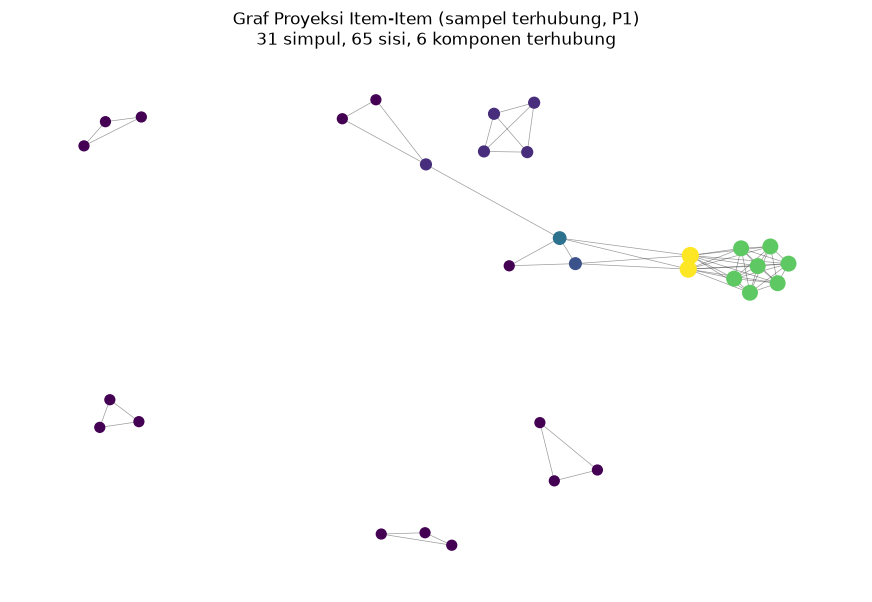

In [13]:
# No. 5 — VSM Item: karakteristik, sampel matriks, dan plot NetworkX
display(karakteristik_vsm(matriks_item, "Item", "Visitor").to_frame())

baris_i, kolom_i = sampel_terhubung(matriks_item, n_perantara=8, deg_min=3, deg_max=15)
print(f"Sampel: {len(baris_i)} item yang dilihat oleh 8 visitor acak (masing-masing berinteraksi dengan 3-15 item)")
display(pd.DataFrame(matriks_item[baris_i[:8]][:, kolom_i].toarray(),
                     index=[item_ids[i] for i in baris_i[:8]],
                     columns=[visitor_ids[j] for j in kolom_i]))

G_item = graf_proyeksi(matriks_item, baris_i, item_ids)
gambar_graf(G_item, "Graf Proyeksi Item-Item (sampel terhubung, P1)",
            os.path.join(OUTPUT_DIR, "graf_proyeksi_item.png"))


### Interpretasi VSM Item

Matriks VSM Item memiliki 87.308 baris dan 185.205 kolom, dengan 266.342 elemen yang terisi. Kepadatan matriks hanya 0,001647%, yang menunjukkan bahwa sebagian besar nilainya kosong. Oleh karena itu, penggunaan *sparse matrix* membantu menghemat memori penyimpanan. Hasil analisis juga menunjukkan bahwa 52,9% Item hanya memiliki interaksi dengan satu Visitor.

Pada contoh matriks, nilai selain nol menunjukkan adanya interaksi antara Item dan Visitor tertentu. Matriks ini digunakan untuk melihat pola interaksi setiap Item dengan Visitor sebagai dasar untuk menghitung kemiripan antaritem.

### Interpretasi Graf Proyeksi Item-Item

Graf proyeksi Item-Item menunjukkan hubungan antaritem yang pernah dilihat oleh Visitor yang sama. Berdasarkan visualisasi, terdapat 31 simpul, 65 sisi, dan 6 komponen terhubung. Item yang saling terhubung memiliki setidaknya satu Visitor yang sama, sedangkan kelompok yang terpisah menunjukkan bahwa tidak ada hubungan antaritem dalam kelompok tersebut pada sampel graf. Graf ini membantu melihat pola kemiripan item berdasarkan interaksi pengunjung.

# 6. Membandingkan proyeksi Visitor dan Item

## Perbandingan Proyeksi Visitor dan Item

In [14]:
# No. 6 — Membandingkan proyeksi pada SELURUH graf P1 (bukan hanya jumlah simpul)

def statistik_proyeksi(B, nama, batas_sisi=20_000_000):
    Bb = B.tocsr().copy()
    Bb.data[:] = 1                                           # biner: ada/tidaknya interaksi
    d = Bb.getnnz(axis=0).astype(np.int64)                   # derajat simpul perantara
    hasil = {"Proyeksi": nama, "Jumlah simpul": Bb.shape[0],
             "Batas atas jumlah sisi": int((d * (d - 1) // 2).sum())}
    if hasil["Batas atas jumlah sisi"] > batas_sisi:
        hasil["Catatan"] = "terlalu besar untuk dihitung penuh"
        return hasil
    t0 = time.perf_counter()
    P = (Bb @ Bb.T).tocsr()
    P.setdiag(0)
    P.eliminate_zeros()
    waktu = time.perf_counter() - t0
    n_komp, label = connected_components(P, directed=False)
    derajat = P.getnnz(axis=1)
    hasil.update({
        "Jumlah sisi": P.nnz // 2,
        "Simpul terisolasi (%)": 100 * (derajat == 0).mean(),
        "Komponen terbesar (% simpul)": 100 * np.bincount(label).max() / Bb.shape[0],
        "Rata-rata derajat": derajat.mean(),
        "Derajat maksimum": int(derajat.max()),
        "Kepadatan graf (%)": 100 * (P.nnz // 2) / (Bb.shape[0] * (Bb.shape[0] - 1) / 2),
        "Memori graf (MB)": (P.data.nbytes + P.indices.nbytes + P.indptr.nbytes) / 1024**2,
        "Waktu proyeksi (detik)": waktu,
    })
    return hasil


def rapikan(df):
    """Tabel tampilan: ribuan dengan titik, desimal dengan koma, lengkap dengan satuan (data numerik tidak diubah)."""
    def angka(x, desimal=0):
        s = f"{x:,.{desimal}f}"
        return s.replace(",", "#").replace(".", ",").replace("#", ".")
    format_baris = {
        "Jumlah simpul": lambda x: angka(x),
        "Batas atas jumlah sisi": lambda x: angka(x),
        "Jumlah sisi": lambda x: angka(x),
        "Simpul terisolasi (%)": lambda x: angka(x, 2) + " %",
        "Komponen terbesar (% simpul)": lambda x: angka(x, 2) + " %",
        "Rata-rata derajat": lambda x: angka(x, 2),
        "Derajat maksimum": lambda x: angka(x),
        "Kepadatan graf (%)": lambda x: angka(x, 4) + " %",
        "Memori graf (MB)": lambda x: angka(x, 1) + " MB",
        "Waktu proyeksi (detik)": lambda x: angka(x, 2) + " detik",
    }
    tampil = df.astype(object).copy()
    for baris, f in format_baris.items():
        if baris in tampil.index:
            tampil.loc[baris] = [f(v) if pd.notna(v) else "-" for v in df.loc[baris]]
    return tampil


df_perbandingan = pd.DataFrame([
    statistik_proyeksi(matriks_visitor, "Visitor-Visitor"),
    statistik_proyeksi(matriks_item, "Item-Item"),
]).set_index("Proyeksi").T          # tetap numerik -> dipakai untuk disimpan ke CSV
display(rapikan(df_perbandingan))   # tabel yang enak dibaca


Proyeksi,Visitor-Visitor,Item-Item
Jumlah simpul,185.205,87.308
Batas atas jumlah sisi,1.674.522,2.256.151
Jumlah sisi,1.620.892,2.150.046
Simpul terisolasi (%),"16,45 %","48,09 %"
Komponen terbesar (% simpul),"56,33 %","41,82 %"
Rata-rata derajat,"17,50","49,25"
Derajat maksimum,9.242,4.326
Kepadatan graf (%),"0,0095 %","0,0564 %"
Memori graf (MB),"25,4 MB","33,1 MB"
Waktu proyeksi (detik),"0,20 detik","0,17 detik"


Berdasarkan hasil perbandingan, graf proyeksi Visitor-Visitor memiliki 185.205 simpul dan 1.620.892 sisi, sedangkan graf Item-Item memiliki 87.308 simpul dan 2.150.046 sisi. Hal ini menunjukkan bahwa meskipun jumlah Item lebih sedikit, hubungan antaritem lebih banyak karena beberapa item dapat dilihat oleh Visitor yang sama.

Pada graf Visitor-Visitor, sebanyak 16,45% simpul tidak memiliki hubungan dengan simpul lain. Sementara itu, pada graf Item-Item, jumlahnya mencapai 48,09%. Rata-rata derajat graf Item-Item juga lebih tinggi, yaitu 49,25 dibandingkan 17,50 pada graf Visitor-Visitor. Artinya, Item cenderung memiliki lebih banyak hubungan dengan Item lain berdasarkan kesamaan Visitor.

Kedua graf memiliki kepadatan yang rendah, sehingga hubungan yang terbentuk hanya mencakup sebagian kecil dari semua kemungkinan hubungan. Proses pembentukan kedua graf membutuhkan waktu sekitar 0,22 detik. Hasil ini menunjukkan bahwa proyeksi Item-Item memiliki lebih banyak hubungan, sedangkan proyeksi Visitor-Visitor memiliki jumlah simpul yang lebih besar.

## Tampilkan perbandingan graf sampel

In [15]:
# Membandingkan hasil graf sampel NetworkX

df_graf = pd.DataFrame({
    "Karakteristik": [
        "Jumlah simpul",
        "Jumlah sisi"
    ],
    "Graf Visitor–Visitor": [
        G_visitor.number_of_nodes(),
        G_visitor.number_of_edges()
    ],
    "Graf Item–Item": [
        G_item.number_of_nodes(),
        G_item.number_of_edges()
    ]
})

display(df_graf)

,Karakteristik,Graf Visitor–Visitor,Graf Item–Item
0,Jumlah simpul,68,31
1,Jumlah sisi,482,65


Berdasarkan hasil perbandingan, graf Visitor–Visitor memiliki 68 simpul dan 482 sisi, sedangkan graf Item–Item memiliki 31 simpul dan 65 sisi. Hal ini menunjukkan bahwa graf Visitor–Visitor memiliki lebih banyak simpul dan hubungan dibandingkan graf Item–Item pada sampel yang digunakan. Dengan demikian, hubungan antarvisitor dalam sampel ini lebih banyak terbentuk dibandingkan hubungan antaritem. Perlu diingat bahwa hasil ini hanya berdasarkan sampel graf, bukan keseluruhan data P1.

## Simpan hasil perbandingan ke CSV

In [16]:
# Menyimpan hasil perbandingan nomor 2.1.6 (revisi sel 56: tabel perbandingan sekarang memakai index)
df_perbandingan.to_csv(os.path.join(OUTPUT_DIR, "perbandingan_proyeksi.csv"))
df_graf.to_csv(os.path.join(OUTPUT_DIR, "perbandingan_graf_sampel.csv"), index=False)
print("Hasil perbandingan berhasil disimpan di folder:", OUTPUT_DIR)


Hasil perbandingan berhasil disimpan di folder: output_21


# 7. Menghitung Similarity antar-Item menggunakan Python

## Menentukan item acuan dan menghitung similarity

In [17]:
# 7.1 Similarity pada graf proyeksi (cosine)

PROYEKSI = "Item"        # "Item" atau "Visitor" -> samakan dengan kesimpulan no. 6
CFG = {
    "Item":    dict(M=matriks_item,    ids=item_ids,    label="Item",    prop="itemId"),
    "Visitor": dict(M=matriks_visitor, ids=visitor_ids, label="Visitor", prop="visitorId"),
}[PROYEKSI]
LABEL, PROP = CFG["label"], CFG["prop"]
M_proy, ids_proy = CFG["M"].tocsr(), CFG["ids"]

ACUAN_ID = None          # None -> simpul dengan derajat tertinggi; isi ID tertentu untuk acuan lain
DERAJAT_MAKS = {"Item": np.inf, "Visitor": 30}[PROYEKSI]   # visitor ekstrem (mis. 888 item) mirip bot -> jangan jadi acuan


def similarity_dari_proyeksi(M, idx, ids, top_n=TOP_K):
    """Cosine(i, j) = P[i, j] / sqrt(P[i, i] * P[j, j]) dengan P = M @ M.T (graf proyeksi berbobot).
    Hanya satu baris P yang dihitung (untuk simpul acuan), jadi tidak perlu menyimpan seluruh proyeksi."""
    p_baris = (M @ M[idx].T).toarray().ravel()                          # P[acuan, :]
    norma = np.sqrt(np.asarray(M.multiply(M).sum(axis=1)).ravel())      # sqrt(P[j, j])
    penyebut = norma * norma[idx]
    sim = np.divide(p_baris, penyebut, out=np.zeros_like(p_baris, dtype=float), where=penyebut > 0)
    Mb = M.copy()
    Mb.data[:] = 1
    bersama = (Mb @ Mb[idx].T).toarray().ravel().astype(int)            # jumlah perantara yang sama
    sim[idx] = 0
    urut = np.argsort(-sim, kind="stable")[:top_n]
    urut = urut[sim[urut] > 0]
    return pd.DataFrame({"acuan": int(ids[idx]), "mirip": [int(ids[j]) for j in urut],
                         "similarity": sim[urut], "bersama": bersama[urut]})


derajat = M_proy.getnnz(axis=1)
idx_acuan = (int(np.argmax(np.where(derajat <= DERAJAT_MAKS, derajat, -1)))
             if ACUAN_ID is None else ids_proy.index(ACUAN_ID))
acuan_id = int(ids_proy[idx_acuan])
print(f"Proyeksi {PROYEKSI}; simpul acuan: {acuan_id} (terhubung ke {derajat[idx_acuan]} simpul lain di graf bipartit)")

df_similarity = similarity_dari_proyeksi(M_proy, idx_acuan, ids_proy)
print("\nLima simpul dengan similarity tertinggi:")
display(df_similarity)


Proyeksi Item; simpul acuan: 5411 (terhubung ke 410 simpul lain di graf bipartit)

Lima simpul dengan similarity tertinggi:


,acuan,mirip,similarity,bersama
0,5411,37807,0.215169,8
1,5411,193409,0.179124,10
2,5411,449224,0.169932,4
3,5411,279006,0.152616,1
4,5411,33030,0.128452,12


Berdasarkan hasil perhitungan cosine similarity, item acuan yang dipilih adalah Item 5411 dipilih sebagai acuan karena paling banyak berinteraksi, yaitu 410 pengunjung unik (451 event) pada P1. Pada graf proyeksi, item ini terhubung dengan 189 item lain yang berbagi minimal satu pengunjung. Dari hasil analisis, diperoleh lima item yang paling mirip, yaitu 37807, 193409, 449224, 279006, dan 33030.

Nilai similarity tertinggi adalah antara Item 5411 dan Item 37807, yaitu 0,215169. Artinya, kedua item tersebut memiliki kemiripan paling tinggi dibandingkan empat item lainnya dalam hasil ini. Kolom bersama menunjukkan jumlah pengunjung yang berinteraksi dengan kedua item tersebut. Hasil ini dapat digunakan sebagai dasar untuk merekomendasikan item lain yang memiliki pola interaksi serupa.

## Simpan lima hasil similarity ke CSV

In [18]:
# 7.2 Menyimpan lima hasil similarity ke CSV

os.makedirs(OUTPUT_DIR, exist_ok=True)

file_similarity = os.path.join(
    OUTPUT_DIR,
    "similarity_item_top5.csv"
)

df_similarity.to_csv(file_similarity, index=False)

print("File berhasil disimpan:")
print(os.path.abspath(file_similarity))

# Membaca kembali file untuk memeriksa hasil penyimpanan
df_similarity_csv = pd.read_csv(file_similarity)
display(df_similarity_csv)


File berhasil disimpan:
h:\SEM 5\GSD\UTS\output_21\similarity_item_top5.csv


,acuan,mirip,similarity,bersama
0,5411,37807,0.215169,8
1,5411,193409,0.179124,10
2,5411,449224,0.169932,4
3,5411,279006,0.152616,1
4,5411,33030,0.128452,12


Hasil perhitungan kemudian disimpan ke dalam file similarity_item_top5.csv pada folder output_21. Penyimpanan ini bertujuan agar hasil perhitungan dapat digunakan kembali dan menjadi dokumentasi hasil analisis.

## Jawaban soal (b): Menuliskan kembali nilai similarity ke graf Neo4j sebagai relasi SIMILAR_TO

In [19]:
# 7.3 Menulis similarity ke graf sebagai relasi SIMILAR_TO 

Q_TULIS = f"""
UNWIND $records AS row
MATCH (a:{LABEL} {{{PROP}: row.acuan}})
MATCH (b:{LABEL} {{{PROP}: row.mirip}})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = row.similarity,
    r.bersama = row.bersama,
    r.period = $periode,
    r.method = 'cosine'
RETURN a.{PROP} AS acuan,
       b.{PROP} AS mirip,
       r.similarity AS similarity,
       r.bersama AS bersama,
       r.period AS periode,
       r.method AS metode
ORDER BY similarity DESC
"""

records_similarity = df_similarity.to_dict("records")
df_hasil_simpan = jalankan_cypher(Q_TULIS, records=records_similarity, periode="P1")
print("Relasi yang dikembalikan Neo4j:")
display(df_hasil_simpan)


Relasi yang dikembalikan Neo4j:


,acuan,mirip,similarity,bersama,periode,metode
0,5411,37807,0.215169,8,P1,cosine
1,5411,193409,0.179124,10,P1,cosine
2,5411,449224,0.169932,4,P1,cosine
3,5411,279006,0.152616,1,P1,cosine
4,5411,33030,0.128452,12,P1,cosine


Hasil perhitungan cosine similarity berhasil disimpan ke Neo4j dalam bentuk relasi SIMILAR_TO. Terdapat lima relasi dari Item 5411 menuju lima item yang paling mirip. Setiap relasi menyimpan nilai similarity, jumlah pengunjung yang berinteraksi dengan kedua item (bersama), periode analisis P1, dan metode perhitungan cosine. Dengan demikian, hasil perhitungan di Python sudah tersimpan di Neo4j dan dapat digunakan untuk melihat hubungan kemiripan antaritem serta mendukung proses rekomendasi.

Urutan similarity tidak mengikuti jumlah pengunjung bersama. Item 33030 punya similarity terendah (0,128452) tetapi berbagi pengunjung terbanyak (12), sedangkan item 279006 (0,152616) hanya didukung 1 pengunjung bersama. Jadi similarity yang tinggi belum tentu didukung bukti yang kuat, dan nilai dari satu pengunjung sebaiknya dibaca hati-hati.

## Jawaban soal (a): Query Cypher untuk mengambil 5 similarity tertinggi

In [20]:
# 7.4 (a) Cypher untuk mengambil 5 similarity tertinggi dari graf 

Q_TOP5 = f"""
MATCH (a:{LABEL} {{{PROP}: $acuan}})-[s:SIMILAR_TO]->(b:{LABEL})
RETURN a.{PROP} AS acuan,
       b.{PROP} AS mirip,
       s.similarity AS similarity,
       s.bersama AS bersama,
       s.period AS periode
ORDER BY s.similarity DESC
LIMIT 5
"""

df_top5_neo4j = jalankan_cypher(Q_TOP5, acuan=acuan_id)
print("Lima similarity tertinggi dari Neo4j:")
display(df_top5_neo4j)


Lima similarity tertinggi dari Neo4j:


,acuan,mirip,similarity,bersama,periode
0,5411,37807,0.215169,8,P1
1,5411,193409,0.179124,10,P1
2,5411,449224,0.169932,4,P1
3,5411,279006,0.152616,1,P1
4,5411,33030,0.128452,12,P1


Berdasarkan hasil query Cypher, Neo4j berhasil menampilkan lima item yang memiliki nilai cosine similarity tertinggi terhadap Item 5411. Hasilnya adalah Item 37807 dengan nilai 0,215169, Item 193409 sebesar 0,179124, Item 449224 sebesar 0,169932, Item 279006 sebesar 0,152616, dan Item 33030 sebesar 0,128452.

Hasil ini sesuai dengan perhitungan sebelumnya di Python. Dengan demikian, relasi SIMILAR_TO berhasil disimpan dan dibaca kembali dari Neo4j dengan nilai kemiripan yang sesuai. Data ini dapat digunakan sebagai dasar untuk memilih item yang direkomendasikan kepada pengguna.

## Visualisasi relasi similarity menggunakan Python

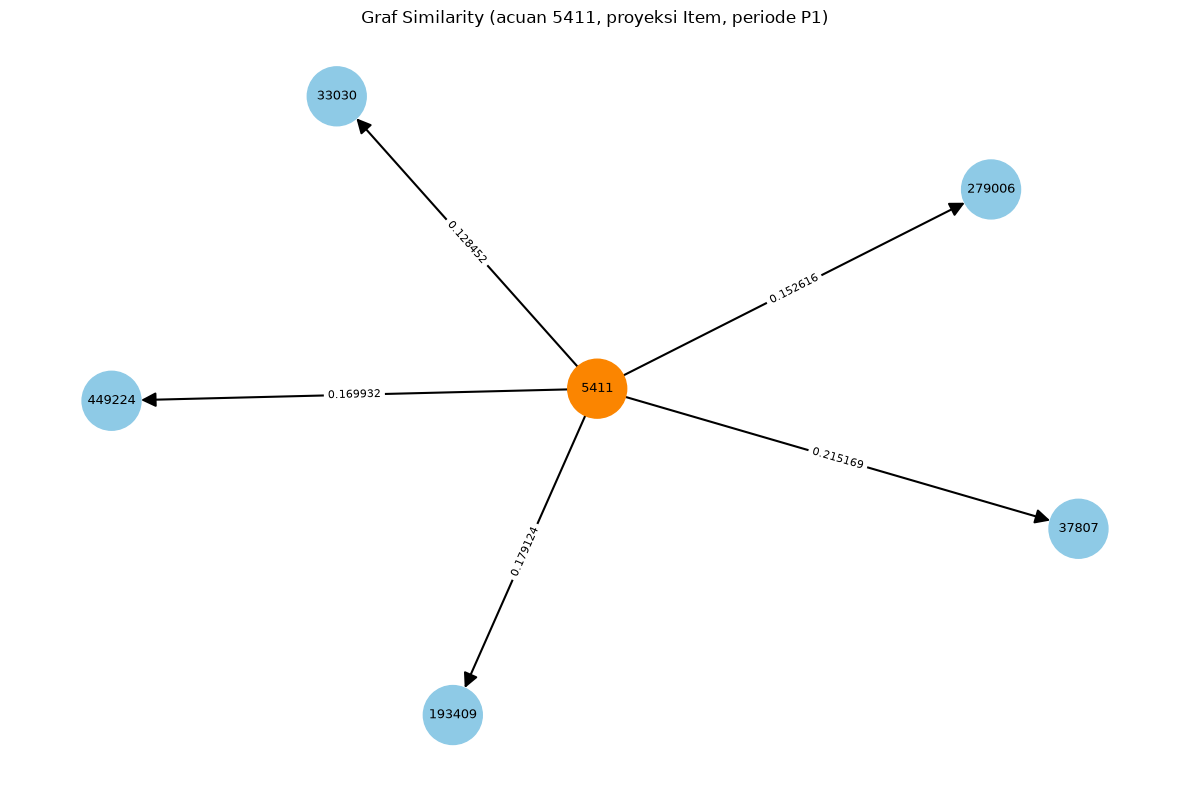

Graf berhasil disimpan di: h:\SEM 5\GSD\UTS\output_21\graf_similarity_python.png


In [21]:
# 7.5 Visualisasi graf similarity 
G_similarity = nx.DiGraph()
for r in df_top5_neo4j.itertuples():
    G_similarity.add_edge(int(r.acuan), int(r.mirip), similarity=float(r.similarity))

pos = nx.spring_layout(G_similarity, seed=RANDOM_SEED)
plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(G_similarity, pos, node_size=1800,
                       node_color=["#fb8500" if n == acuan_id else "#8ecae6" for n in G_similarity])
nx.draw_networkx_labels(G_similarity, pos, font_size=9)
nx.draw_networkx_edges(G_similarity, pos, arrows=True, arrowsize=22, width=1.5, node_size=1800)
nx.draw_networkx_edge_labels(
    G_similarity, pos,
    edge_labels={(u, v): f"{d['similarity']:.6f}" for u, v, d in G_similarity.edges(data=True)},
    font_size=8,
)
plt.title(f"Graf Similarity (acuan {acuan_id}, proyeksi {PROYEKSI}, periode P1)")
plt.axis("off")
plt.tight_layout()
file_graf = os.path.join(OUTPUT_DIR, "graf_similarity_python.png")
plt.savefig(file_graf, dpi=300, bbox_inches="tight")
plt.show()
print("Graf berhasil disimpan di:", os.path.abspath(file_graf))


Graf menunjukkan hubungan kemiripan antara item acuan 5411 dengan lima item lain pada periode P1 menggunakan metode cosine similarity. Node berwarna oranye merupakan item acuan, sedangkan node berwarna biru merupakan item yang memiliki kemiripan dengannya. Arah panah menunjukkan hubungan dari item acuan menuju item yang mirip, dan angka pada setiap garis menunjukkan nilai cosine similarity.

Item 37807 memiliki nilai kemiripan tertinggi sebesar 0,215169, diikuti item 193409 sebesar 0,179124, item 449224 sebesar 0,169932, item 279006 sebesar 0,152616, dan item 33030 sebesar 0,128452.

Berdasarkan visualisasi tersebut, item 37807 merupakan item yang paling mirip dengan item 5411 di antara lima item yang ditampilkan. Semakin tinggi nilai cosine similarity, semakin mirip pola interaksi kedua item berdasarkan data periode P1. Graf ini dapat digunakan untuk membantu menentukan kandidat item yang berpotensi direkomendasikan kepada pengguna.

## Simpan hasil query dan graf

In [22]:
# 7.6 Menyimpan hasil query dan graf 

file_tabel = os.path.join(
    OUTPUT_DIR,
    "hasil_query_similarity_neo4j.csv"
)

df_top5_neo4j.to_csv(file_tabel, index=False)

print("Tabel hasil query:", os.path.abspath(file_tabel))
print("Gambar graf:", os.path.abspath(file_graf))

Tabel hasil query: h:\SEM 5\GSD\UTS\output_21\hasil_query_similarity_neo4j.csv
Gambar graf: h:\SEM 5\GSD\UTS\output_21\graf_similarity_python.png


# 8. Menampilkan Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

SIMILAR_TO sebelum perhitungan: 0
SIMILAR_TO sesudah perhitungan: 5


,acuan,mirip,similarity,bersama,periode
0,5411,37807,0.215169,8,P1
1,5411,193409,0.179124,10,P1
2,5411,449224,0.169932,4,P1
3,5411,279006,0.152616,1,P1
4,5411,33030,0.128452,12,P1


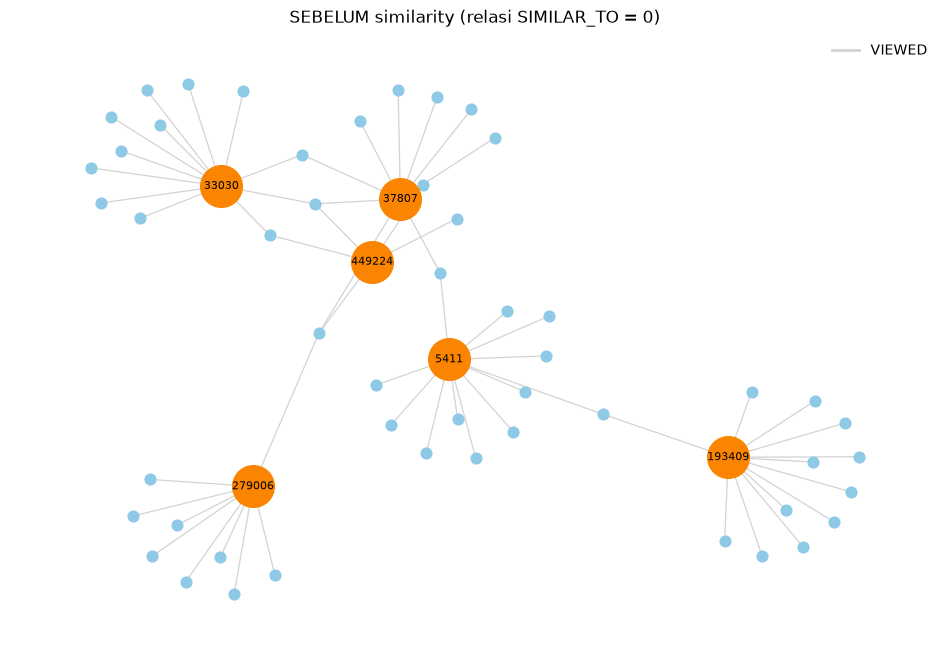

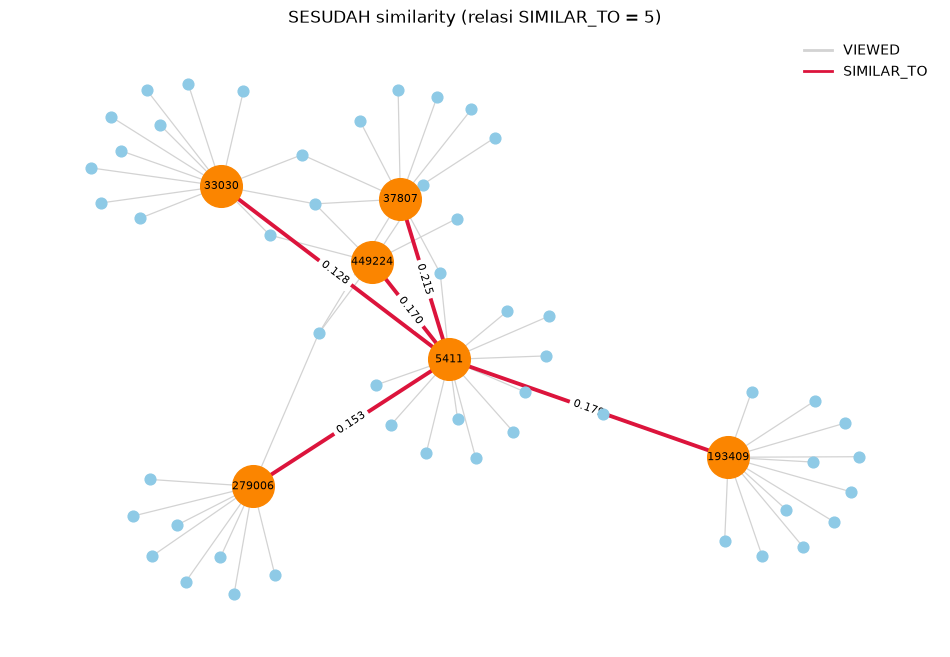

In [23]:
# 8. Kondisi SEBELUM dan SESUDAH perhitungan similarity, pada subgraf yang SAMA
from matplotlib.lines import Line2D

Q_HITUNG = "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to"
Q_HAPUS = "MATCH ()-[s:SIMILAR_TO]->() DELETE s"          # hanya relasi SIMILAR_TO, bukan seluruh database

KONDISI = "i.itemId IN $ids" if LABEL == "Item" else "v.visitorId IN $ids"
Q_INTERAKSI = f"""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE {KONDISI} AND r.timestamp >= $awal AND r.timestamp < $akhir
RETURN DISTINCT v.visitorId AS visitor, i.itemId AS item, type(r) AS jenis
"""

simpul_uji = [acuan_id] + df_similarity["mirip"].tolist()        # acuan + 5 simpul paling mirip
N_PER_SIMPUL = 12                                                # batasi agar gambar terbaca

# ---- SEBELUM: kosongkan SIMILAR_TO, lalu ukur kondisi awal
jalankan_cypher(Q_HAPUS)
n_sebelum = int(jalankan_cypher(Q_HITUNG).iloc[0, 0])
df_int = jalankan_cypher(Q_INTERAKSI, ids=simpul_uji, awal=p1_start, akhir=p1_end)
assert df_int[("item" if LABEL == "Item" else "visitor")].isin(simpul_uji).all()      # subgraf hanya memuat simpul uji
print("SIMILAR_TO sebelum perhitungan:", n_sebelum)

# ---- Tulis ulang similarity (Q_TULIS dari sel 7.3)
jalankan_cypher(Q_TULIS, records=records_similarity, periode="P1")

# ---- SESUDAH
n_sesudah = int(jalankan_cypher(Q_HITUNG).iloc[0, 0])
df_sim_sesudah = jalankan_cypher(Q_TOP5, acuan=acuan_id)
print("SIMILAR_TO sesudah perhitungan:", n_sesudah)
display(df_sim_sesudah)

# ---- Sampel deterministik yang sama untuk kedua gambar
kolom_pusat = "item" if LABEL == "Item" else "visitor"
URUTAN = {"BOUGHT": 0, "ADDED_TO_CART": 1, "VIEWED": 2}        # utamakan relasi beli/keranjang agar ketiga jenis terlihat
sampel = (df_int.assign(prioritas=df_int["jenis"].map(URUTAN))
                .sort_values([kolom_pusat, "prioritas", "visitor", "item"])
                .groupby(kolom_pusat).head(N_PER_SIMPUL))


def bangun_graf(sampel, df_sim=None):
    G = nx.Graph()
    for s in simpul_uji:
        G.add_node(f"{LABEL[0]}{s}", pusat=True)
    for r in sampel.itertuples():
        G.add_node(f"V{r.visitor}", pusat=(LABEL == "Visitor" and r.visitor in simpul_uji))
        G.add_node(f"I{r.item}", pusat=(LABEL == "Item" and r.item in simpul_uji))
        if not G.has_edge(f"V{r.visitor}", f"I{r.item}"):
            G.add_edge(f"V{r.visitor}", f"I{r.item}", jenis=r.jenis)
    if df_sim is not None:
        for r in df_sim.itertuples():
            G.add_edge(f"{LABEL[0]}{r.acuan}", f"{LABEL[0]}{r.mirip}", jenis="SIMILAR_TO", similarity=r.similarity)
    return G


def gambar_kondisi(G, pos, judul, file):
    warna = {"VIEWED": "lightgray", "ADDED_TO_CART": "darkorange", "BOUGHT": "seagreen", "SIMILAR_TO": "crimson"}
    fig, ax = plt.subplots(figsize=(12, 8))
    for jenis, w in warna.items():
        e = [(u, v) for u, v, d in G.edges(data=True) if d["jenis"] == jenis]
        if e:
            nx.draw_networkx_edges(G, pos, edgelist=e, edge_color=w, ax=ax,
                                   width=2.8 if jenis == "SIMILAR_TO" else 0.9)
    pusat = [n for n, d in G.nodes(data=True) if d["pusat"]]
    lain = [n for n in G if n not in pusat]
    nx.draw_networkx_nodes(G, pos, nodelist=lain, node_color="#8ecae6", node_size=60, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=pusat, node_color="#fb8500", node_size=900, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n[1:] for n in pusat}, font_size=8, ax=ax)
    label_sim = {(u, v): f"{d['similarity']:.3f}" for u, v, d in G.edges(data=True) if d["jenis"] == "SIMILAR_TO"}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=label_sim, font_size=8, ax=ax)
    ada = {d["jenis"] for _, _, d in G.edges(data=True)}                       # legenda hanya untuk jenis yang muncul
    ax.legend(handles=[Line2D([0], [0], color=c, lw=2, label=j) for j, c in warna.items() if j in ada],
              loc="upper right", frameon=False)
    ax.set_title(judul)
    ax.axis("off")
    fig.savefig(file, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()


G_sebelum = bangun_graf(sampel)
G_sesudah = bangun_graf(sampel, df_sim_sesudah)
pos = nx.spring_layout(G_sesudah, seed=RANDOM_SEED, k=1.2, iterations=300)      # posisi sama -> perbedaannya mudah dilihat
gambar_kondisi(G_sebelum, pos, f"SEBELUM similarity (relasi SIMILAR_TO = {n_sebelum})",
               os.path.join(OUTPUT_DIR, "graf_sebelum_similarity.png"))
gambar_kondisi(G_sesudah, pos, f"SESUDAH similarity (relasi SIMILAR_TO = {n_sesudah})",
               os.path.join(OUTPUT_DIR, "graf_sesudah_similarity.png"))


Berdasarkan hasil pengujian, sebelum perhitungan similarity dilakukan, terdapat 0 relasi SIMILAR_TO di Neo4j. Graf hanya menampilkan hubungan interaksi antara pengunjung dan item, seperti VIEWED, ADDED_TO_CART, dan BOUGHT.

Setelah perhitungan cosine similarity disimpan ke Neo4j, jumlah relasi SIMILAR_TO menjadi 5, sesuai dengan lima item yang memiliki nilai kemiripan tertinggi terhadap item acuan 5411. Item tersebut adalah 37807, 193409, 449224, 279006, dan 33030.

Pada graf sesudah perhitungan, relasi SIMILAR_TO ditampilkan dengan garis merah, sedangkan hubungan interaksi ditampilkan dengan garis abu-abu. Nilai similarity pada garis merah menunjukkan tingkat kemiripan antara item acuan dan item lainnya. Item 37807 memiliki nilai similarity tertinggi, yaitu 0,215169, sedangkan item 33030 memiliki nilai terendah di antara lima item tersebut, yaitu 0,128452.

Dengan demikian, visualisasi membuktikan bahwa proses perhitungan dan penyimpanan similarity berhasil dilakukan. Kedua graf menggunakan kumpulan simpul dan posisi yang sama sehingga perubahan hubungan sebelum dan sesudah perhitungan dapat dibandingkan dengan lebih mudah. Hasil ini dapat digunakan sebagai dasar untuk menentukan item yang berpotensi direkomendasikan.